# Pipeline de streams: las 10 etapas de punta a punta

Proyecto *pipeline-streams-eda* · Estructuras de Datos y Algoritmos (UTEC, 2026-2) · dataset **REES46**

Este cuaderno corre el **pipeline completo** con el orquestador `src/pipeline.py`, el mismo
que usan `run_pipeline.py`, el panel de Streamlit y las pruebas. Sirve para la demo de la
exposición: con **datos sintéticos** (rápido, trae todos los casos) o con **datos reales de
REES46** (el CSV de octubre de 2019, al que se le agregan los campos del stream).

| | Etapa de flujo (por lote) | Estructura |
|---|---|---|
| 0 | Ingesta y buffer | cola FIFO / buffer circular |
| 1 | Preprocesamiento | merge sort + búsqueda binaria |
| 6 | Fraude | filtro de Bloom + Count-Min Sketch |
| 2 | Prioridad | min-heap |
| 3 | Lookup y caché | tabla hash + LRU + matriz dispersa |
| 4 | Índice | B+Tree |
| 8 | Grafo de co-compra | grafo + PageRank + Louvain |

| | Etapa sobre el catálogo (al cerrar) | Estructura |
|---|---|---|
| 5 | Índice multidimensional | k-d tree + k-NN |
| 7 | Similitud aproximada | IVF + MinHash LSH |
| 9 | Servicio | trie + top-k |

El orden de flujo es `0 → 1 → 6 → 2 → 3 → 4 → 8`: la etapa 6 va antes de la 2 para que la
prioridad use la decisión de fraude. Al cerrar el stream se arman las etapas 5, 7 y 9.

**Cómo usarlo:** elige la fuente en la celda de configuración y ejecuta todo
(*Run All*). Cada sección muestra una etapa con datos de esta corrida.

## 0. Configuración

| Fuente | Qué usa | Tiempo aproximado |
|---|---|---|
| `"sintetico"` | `generar_stream`: duplicados, inválidos, express, programadas, compras conjuntas y fraude | 10K eventos: unos segundos |
| `"real"` | Filas del CSV de REES46 + campos del stream agregados (`aumentar_filas`) | 20K filas: menos de 1 min · 100K: unos 2–3 min |

Con datos reales, la etapa 7 (IVF) es la más lenta, porque el catálogo real es grande.
Para la demo en vivo conviene `LIMITE_REAL = 20_000`. El CSV va en `data/raw/`, que git
ignora: nunca se sube al repositorio.

In [1]:
FUENTE = "sintetico"          # "sintetico" o "real"

N_SINTETICO = 10_000          # eventos del stream sintético
RUTA_CSV = "data/raw/2019-Oct_2M.csv"   # CSV de REES46 (relativo a la raíz del proyecto)
LIMITE_REAL = 20_000          # filas a leer del CSV

SEMILLA = 42
CACHE = None                  # capacidad de la caché LRU; None = ~10 % del catálogo esperado
CONSULTAS_CACHE = 20_000      # visitas simuladas a fichas para medir la caché

In [2]:
import os
import sys
from time import perf_counter

RAIZ = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.path.abspath(".")
if RAIZ not in sys.path:
    sys.path.insert(0, RAIZ)

import matplotlib.pyplot as plt

from experimentos.stream_completo import aumentar_filas, generar_stream
from src.etapa0_ingesta import leer_csv
from src.etapa2_prioridad.prioridad import NOMBRES
from src.etapa8_grafo.ranking import correlacion_rangos
from src.pipeline import ETAPAS, ORDEN_CIERRE, ORDEN_FLUJO, Pipeline

ACENTO, GRIS = "#B04A15", "#3D4856"


def num(x, decimales=0):
    """Número con punto de miles y coma decimal: 12.345,67."""
    return f"{x:,.{decimales}f}".replace(",", "_").replace(".", ",").replace("_", ".")
ETIQUETA_NIVEL = {"fraude_o_pago": "0 fraude o pago", "express": "1 express", "estandar": "2 estándar",
                  "programada": "3 programada", "baja": "4 navegación"}


def cargar(fuente):
    """Devuelve (stream, lista_negra, descripción, productos esperados en el catálogo)."""
    if fuente == "sintetico":
        stream, lista_negra = generar_stream(N_SINTETICO, semilla=SEMILLA)
        # el generador arma un catálogo de n/20 productos
        return stream, lista_negra, f"{num(N_SINTETICO)} eventos sintéticos", max(60, N_SINTETICO // 20)
    if fuente == "real":
        ruta = os.path.join(RAIZ, RUTA_CSV)
        if not os.path.exists(ruta):
            raise FileNotFoundError(f"No encuentro {ruta}. Pon el CSV de REES46 en data/raw/ o cambia RUTA_CSV.")
        # una pasada rápida por las filas para saber cuántos productos distintos hay
        productos = len({fila["product_id"] for fila in leer_csv(ruta, limite=LIMITE_REAL)})
        stream, lista_negra = aumentar_filas(leer_csv(ruta, limite=LIMITE_REAL), semilla=SEMILLA)
        return stream, lista_negra, f"{num(LIMITE_REAL)} filas reales de {RUTA_CSV}", productos
    raise ValueError('FUENTE debe ser "sintetico" o "real"')


def correr(fuente):
    stream, lista_negra, descripcion, productos = cargar(fuente)
    capacidad = CACHE or max(10, productos // 10)   # caché del ~10 % del catálogo
    inicio = perf_counter()
    pipe = Pipeline(lista_negra=lista_negra, semilla=SEMILLA, capacidad_cache=capacidad)
    pipe.procesar(stream).cerrar()
    return pipe, descripcion, capacidad, perf_counter() - inicio


print("Entorno listo. Raíz:", RAIZ)

Entorno listo. Raíz: D:\#CFUKUMOTO\MASTER\ciclo 2\Estructura de Datos y Algoritmos\proyecto\pipeline-streams-eda


## 1. Correr el pipeline completo

El orquestador procesa el stream lote por lote (etapas de flujo) y luego **cierra** el
stream para armar las etapas sobre el catálogo.

In [3]:
pipe, descripcion, capacidad_cache, total = correr(FUENTE)
resumen = pipe.resumen()
print(f"Fuente: {descripcion}")
print(f"Pipeline procesado y cerrado en {num(total, 1)} s")

Fuente: 10.000 eventos sintéticos
Pipeline procesado y cerrado en 1,1 s


## 2. Qué pasó en cada etapa

`resumen()` devuelve las métricas de las 10 etapas, en el orden en que corren.

In [4]:
def fmt(v):
    if isinstance(v, float):
        return f"{num(v, 3)}"
    if isinstance(v, dict):
        return ", ".join(f"{k}={fmt(x)}" for k, x in v.items())
    return str(v)


print(f"{'#':>2}  {'Etapa':<46} {'Tiempo':>9}   Métricas")
print("-" * 110)
for etapa in ORDEN_FLUJO + ORDEN_CIERRE:
    print(f"{etapa:>2}  {ETAPAS[etapa]:<46} {num(pipe.tiempos[etapa], 3):>8}s   {fmt(resumen[etapa])}")
print(f"{'':>2}  {'Total':<46} {num(total, 3):>8}s")

 #  Etapa                                             Tiempo   Métricas
--------------------------------------------------------------------------------------------------------------
 0  Ingesta y buffer                                  0,005s   lotes=10, eventos_recibidos=10000
 1  Preprocesamiento por lotes                        0,071s   validos=9594, descartados=105, duplicados=301
 6  Filtrado probabilístico (fraude)                  0,230s   marcados=613, precision=1,000, recall=1,000
 2  Cola con prioridades                              0,047s   fraude_o_pago=613, express=225, estandar=595, programada=113, baja=8048
 3  Lookup y caché                                    0,028s   productos=497, matriz_celdas=8503, compras_celdas=1138
 4  Índice principal (B+Tree)                         0,016s   eventos_indexados=9594, altura_tiempo=3, altura_precio=2
 8  Grafo de co-compra                                0,004s   compras=1142, productos=367, aristas=1189
 5  Índice multidimensiona

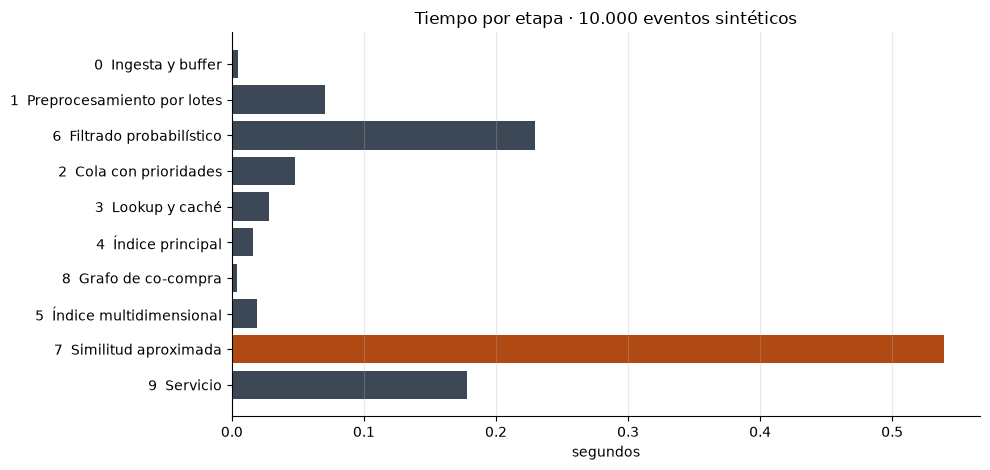

La etapa más lenta es la 7 (Similitud aproximada (IVF y MinHash + LSH)): 47 % del total.


In [5]:
etapas = ORDEN_FLUJO + ORDEN_CIERRE
tiempos = [pipe.tiempos[e] for e in etapas]
etiquetas = [f"{e}  {ETAPAS[e].split('(')[0].strip()}" for e in etapas]
mas_lenta = max(range(len(tiempos)), key=tiempos.__getitem__)

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.barh(etiquetas, tiempos, color=[ACENTO if i == mas_lenta else GRIS for i in range(len(tiempos))])
ax.invert_yaxis()
ax.set_xlabel("segundos")
ax.set_title(f"Tiempo por etapa · {descripcion}")
ax.grid(True, axis="x", alpha=.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()
print(f"La etapa más lenta es la {etapas[mas_lenta]} ({ETAPAS[etapas[mas_lenta]]}): "
      f"{num(100 * tiempos[mas_lenta] / total, 0)} % del total.")

## 3. Ingesta y limpieza (etapas 0 y 1)

La etapa 0 recibe el stream en una cola FIFO y lo entrega en lotes. La etapa 1 valida,
ordena por tiempo con merge sort y descarta los duplicados del lote.

In [6]:
m0, m1 = resumen[0], resumen[1]
print(f"Etapa 0: {num(m0['eventos_recibidos'])} eventos en {m0['lotes']} lotes")
print(f"Etapa 1: {num(m1['validos'])} válidos, {num(m1['descartados'])} descartados y {num(m1['duplicados'])} duplicados")

Etapa 0: 10.000 eventos en 10 lotes
Etapa 1: 9.594 válidos, 105 descartados y 301 duplicados


## 4. Detección de fraude (etapa 6)

Bloom para la lista negra y Count-Min para las ráfagas. Lo marcado como fraude sale primero
en la etapa 2. La calidad se mide contra `es_fraude`, la etiqueta del generador, que nunca se
usa para decidir. Con datos reales el fraude es sintético: REES46 no trae IP ni dispositivo.

In [7]:
m6 = resumen[6]
print(f"Eventos marcados como fraude: {num(m6['marcados'])}")
print(f"Precisión: {num(m6['precision'], 3)}   Recall: {num(m6['recall'], 3)}")
print("\nAlertas más urgentes (orden de prioridad):")
for a in pipe.servicio.alertas[:6]:
    print(f"  {a['event_type']:<9} producto {a['product_id']}  usuario {a['user_id']}  "
          f"score {a['score']}  ({a['motivos']})")

Eventos marcados como fraude: 613
Precisión: 1,000   Recall: 1,000

Alertas más urgentes (orden de prioridad):
  view      producto 1000020  usuario 501942630  score 0.825  (rafaga)
  purchase  producto 1000043  usuario 501942630  score 0.825  (rafaga)
  cart      producto 1000065  usuario 501942630  score 0.825  (rafaga)
  cart      producto 1000115  usuario 501942630  score 0.825  (rafaga)
  purchase  producto 1000181  usuario 501942630  score 0.825  (rafaga)
  view      producto 1000181  usuario 501942630  score 0.825  (rafaga)


## 5. Cola con prioridades (etapa 2)

Un MinHeap con la clave `(prioridad, event_time, contador, evento)`: sale primero el número
menor y, a igual prioridad, el más antiguo. Para verlo, se toma un lote chico con 2 eventos de
cada nivel y se compara el **orden de llegada** con el **orden de atención**.

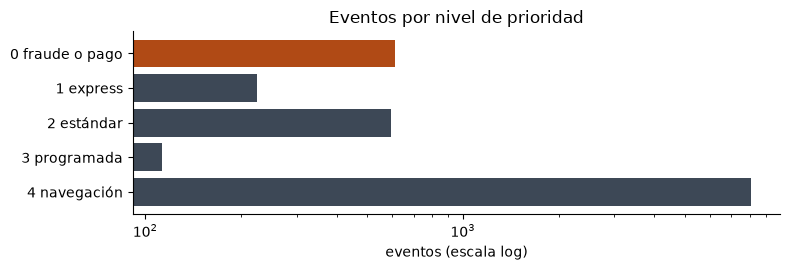

   Orden de llegada                         Orden de atención (sale del heap)
 1 00:03:04  cart     0 fraude o pago       00:03:04  cart     0 fraude o pago 
 2 00:06:16  purchase 3 programada          00:14:13  view     0 fraude o pago 
 3 00:07:27  view     4 navegación          00:24:47  purchase 1 express       
 4 00:14:13  view     0 fraude o pago       01:01:33  purchase 1 express       
 5 00:24:47  purchase 1 express             00:28:34  purchase 2 estándar      
 6 00:28:34  purchase 2 estándar            00:32:20  purchase 2 estándar      
 7 00:32:20  purchase 2 estándar            00:06:16  purchase 3 programada    
 8 00:47:58  purchase 3 programada          00:47:58  purchase 3 programada    
 9 00:49:45  view     4 navegación          00:07:27  view     4 navegación    
10 01:01:33  purchase 1 express             00:49:45  view     4 navegación    


In [8]:
from datetime import datetime, timezone

conteo = resumen[2]
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.barh([ETIQUETA_NIVEL[k] for k in conteo], list(conteo.values()), color=[ACENTO] + [GRIS] * 4)
ax.invert_yaxis(); ax.set_xscale("log"); ax.set_xlabel("eventos (escala log)")
ax.set_title("Eventos por nivel de prioridad")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

llegada, atencion = pipe.lote_de_prioridades(por_nivel=2, semilla=SEMILLA)


def fila(e):
    hora = datetime.fromtimestamp(e["event_time"], tz=timezone.utc).strftime("%H:%M:%S")
    nivel = ETIQUETA_NIVEL[NOMBRES[int(e["prioridad"])]]
    return f"{hora}  {e['event_type']:<8} {nivel:<16}"


print(f"   {'Orden de llegada':<38}   Orden de atención (sale del heap)")
for i, (a, b) in enumerate(zip(llegada, atencion), 1):
    print(f"{i:>2} {fila(a):<38}   {fila(b)}")

## 6. Lookup y caché (etapa 3)

La tabla hash guarda una ficha por producto (no por evento) y la encuentra en O(1). Delante
va una caché LRU para los productos populares. Se simulan visitas a fichas con la popularidad
observada (vistas) para medir cuántas resuelve la caché sin tocar la tabla.

In [9]:
producto = pipe.influyentes(1)[0][0]
ficha = pipe.consultar_producto(producto)
print(f"Ficha del producto {producto}: categoría {ficha['category_code']}, marca {ficha['brand']}, "
      f"precio {ficha['price']}, {ficha['vistas']} vistas, {ficha['compras']} compras")

catalogo = len(pipe.e3.catalogo)
tasa = pipe.simular_consultas(n=CONSULTAS_CACHE, semilla=SEMILLA)
print(f"\nCatálogo: {num(catalogo)} productos en la tabla hash ({num(pipe.e3.catalogo.capacidad)} cubetas, "
      f"carga {num(pipe.e3.catalogo.factor_carga, 2)})")
print(f"Caché LRU de {num(capacidad_cache)} productos ({num(100 * capacidad_cache / catalogo, 0)} % del catálogo): "
      f"acertó el {num(100 * tasa, 1)} % de {num(CONSULTAS_CACHE)} visitas")
print(f"Matriz usuario × producto dispersa: {num(resumen[3]['matriz_celdas'])} celdas no nulas")

Ficha del producto 1000273: categoría computers.notebook, marca lucente, precio 1642.0, 1064 vistas, 49 compras

Catálogo: 497 productos en la tabla hash (1.024 cubetas, carga 0,49)
Caché LRU de 50 productos (10 % del catálogo): acertó el 48,5 % de 20.000 visitas
Matriz usuario × producto dispersa: 8.503 celdas no nulas


## 7. Índice con B+Tree (etapa 4)

Dos índices de orden 64: por tiempo (eventos entre dos instantes) y por precio (productos en
un rango). Una consulta por rango baja una vez hasta la primera hoja y avanza por las hojas
enlazadas: O(log n + k).

In [10]:
m4 = resumen[4]
print(f"Eventos indexados: {num(m4['eventos_indexados'])} · altura del índice por tiempo: {m4['altura_tiempo']} · "
      f"por precio: {m4['altura_precio']}")

desde, hasta = 100, 300
rango = pipe.productos_por_precio(desde, hasta)
print(f"\nProductos con precio entre {desde} y {hasta}: {num(len(rango))}. Los primeros:")
for precio, pid in rango[:8]:
    print(f"  {num(precio, 2):>10}  producto {pid}")

inicio_t = min(e["event_time"] for e in pipe.eventos)
en_un_minuto = pipe.eventos_entre(inicio_t, inicio_t + 60)
print(f"\nEventos en el primer minuto del stream: {num(len(en_un_minuto))}")

Eventos indexados: 9.594 · altura del índice por tiempo: 3 · por precio: 2

Productos con precio entre 100 y 300: 62. Los primeros:
      105,90  producto 1000347
      105,92  producto 1000067
      111,25  producto 1000470
      113,14  producto 1000258
      123,98  producto 1000240
      125,92  producto 1000062
      126,35  producto 1000361
      126,61  producto 1000076

Eventos en el primer minuto del stream: 135


## 8. Grafo de co-compra (etapa 8)

Nodos: productos. Arista: dos productos comprados en la misma sesión; el peso cuenta cuántas
veces. PageRank encuentra los productos influyentes y Louvain los grupos de consumo. Se
comparan con sus alternativas: ranking por grado y Label Propagation.

Con datos reales el grafo es mucho más chico: comprar dos productos en la misma sesión es
raro, así que hacen falta muchos más eventos para que aparezca estructura.

In [11]:
m8 = pipe.e8.metricas(con_comunidades=True)
print(f"Grafo: {num(m8['productos'])} productos y {num(m8['aristas'])} aristas, de {num(m8['compras'])} compras")

pr, grado = pipe.e8.puntajes("pagerank"), pipe.e8.puntajes("grado")
top_pr = [p for p, _ in pipe.e8.influyentes(10, "pagerank")]
top_grado = [p for p, _ in pipe.e8.influyentes(10, "grado")]
print(f"\nPageRank frente a grado: Spearman {num(correlacion_rangos(pr, grado), 3)}, "
      f"{len(set(top_pr) & set(top_grado))} de 10 coinciden en el Top-10")
print("Top-5 por PageRank:")
for p, s in pipe.e8.influyentes(5, "pagerank"):
    print(f"  producto {p}  {num(s, 6)}  (grado ponderado {num(grado[p])})")

print(f"\n{'Comunidades':<20} {'grupos':>7} {'mayor':>7} {'modularidad':>12}")
for metodo, nombre in (("louvain", "Louvain"), ("label_propagation", "Label Propagation")):
    if metodo in m8:
        c = m8[metodo]
        print(f"{nombre:<20} {num(c['comunidades']):>7} {num(c['tamanos'][0] if c['tamanos'] else 0):>7} "
              f"{num(c['modularidad'], 3):>12}")

Grafo: 367 productos y 1.189 aristas, de 1.142 compras

PageRank frente a grado: Spearman 0,822, 10 de 10 coinciden en el Top-10
Top-5 por PageRank:
  producto 1000273  0,014262  (grado ponderado 90)
  producto 1000375  0,014171  (grado ponderado 93)
  producto 1000309  0,011489  (grado ponderado 78)
  producto 1000297  0,011190  (grado ponderado 62)
  producto 1000057  0,011115  (grado ponderado 75)

Comunidades           grupos   mayor  modularidad
Louvain                   40      31        0,726
Label Propagation         83      14        0,636


## 9. Similitud y servicio (etapas 5, 7 y 9)

Al cerrar el stream, la etapa 5 indexa los productos en un KD-Tree, la 7 arma IVF (vectores) y
MinHash + LSH (compradores en común), y la 9 sirve recomendaciones, autocompletado e
influencia. Cada método aproximado se compara contra su versión exacta (recall@5).

In [12]:
demo = pipe.evento_para_demo()
pid = demo["product_id"]
print(f"Recomendaciones para el producto {pid}:")
for p, s in pipe.servicio.recomendar(pid, k=3):
    print(f"  producto {p}  (relevancia {num(s, 3)})")
print("Autocompletar 'sa':", pipe.servicio.autocompletar("sa", k=5))

print(f"\n{'Método':<15} {'recall@5':>9} {'ms/consulta':>12}   contra")
for metodo, f in pipe.comparar_similitud(k=5).items():
    if f["consultas"]:
        print(f"{metodo:<15} {num(f['recall'], 2):>9} {num(f['ms_por_consulta'], 3):>12}   {f['contra']}")
    else:
        print(f"{metodo:<15} {'—':>9} {'—':>12}   sin productos con compradores en común")

Recomendaciones para el producto 1000043:
  producto 1000049  (relevancia 0,953)
  producto 1000469  (relevancia 0,929)
  producto 1000325  (relevancia 0,914)
Autocompletar 'sa': ['samsung']

Método           recall@5  ms/consulta   contra


knn_exacto           1,00        0,872   es la referencia
kd_tree              1,00        0,526   knn_exacto
ivf                  1,00        0,441   knn_exacto
jaccard_exacto       1,00        0,077   es la referencia
minhash_lsh          0,87        0,033   jaccard_exacto


## 10. Panel de ventas

Compras confirmadas: las que la etapa 6 marcó como fraude quedan retenidas y no cuentan. Lo
más vendido sale de un Top-K con el heap, sin ordenar todo el catálogo.

In [13]:
v = pipe.ventas(k=5)
print(f"Ventas: {num(v['ventas'])} · retenidas por fraude: {num(v['retenidas_por_fraude'])} · "
      f"ingresos: {num(v['ingresos'], 2)} · ticket promedio: {num(v['ticket_promedio'], 2)} · "
      f"conversión: {num(100 * v['conversion'], 1)} %")
print("\nMás vendidos (por ingresos):")
for p, marca, unidades, total_p in v["mas_vendidos"]:
    print(f"  producto {p:<10} {marca:<12} {unidades:>4} u.  {num(total_p, 2):>12}")
print("\nVentas por tipo de orden:", {ETIQUETA_NIVEL.get(k, k): n for k, n in v["por_tipo_orden"].items()})

Ventas: 933 · retenidas por fraude: 209 · ingresos: 929.036,61 · ticket promedio: 995,75 · conversión: 37,1 %

Más vendidos (por ingresos):
  producto 1000273    lucente        47 u.     77.174,00
  producto 1000378    lg             30 u.     52.105,20
  producto 1000375    sony           30 u.     48.734,40
  producto 1000435    bosch          25 u.     26.263,00
  producto 1000089    apple          13 u.     22.868,82

Ventas por tipo de orden: {'1 express': 225, '2 estándar': 595, '3 programada': 113}


## 11. El recorrido de un evento por las 10 etapas

La mejor forma de ver el pipeline integrado: un evento (de preferencia una compra marcada
como fraude) y **qué le pasó en cada etapa**.

In [14]:
evento = pipe.evento_para_demo()
print(f"Evento: {evento['event_type']} del producto {evento['product_id']} (usuario {evento['user_id']})\n")
for etapa, nombre, resultado in pipe.recorrido(evento):
    print(f"  {etapa}  {nombre:<44} {resultado}")

Evento: purchase del producto 1000043 (usuario 501942630)

  0  Ingesta y buffer                             entró por la cola FIFO en uno de los 10 lotes
  1  Preprocesamiento por lotes                   válido y sin duplicar; event_time normalizado a 1569888002
  6  Filtrado probabilístico (fraude)             marcado como fraude (score 0.825, motivos: rafaga)
  2  Cola con prioridades                         prioridad 0 (fraude_o_pago)
  3  Lookup y caché                               ficha del producto 1000043: 0 vistas, 0 carritos, 1 compras, categoría electronics.audio.headphone
  4  Índice principal (B+Tree)                    precio vigente 1858.55; 14 eventos en el mismo segundo
  8  Grafo de co-compra                           puesto 184 de 367 en PageRank; comprado junto con [1000181, 1000204, 1000224]
  5  Índice multidimensional (KD-Tree)            vecinos más cercanos en el KD-Tree: [1000049, 1000469, 1000325]
  7  Similitud aproximada (IVF y MinHash + LSH)   recomendado

## 12. El porqué de las estructuras: memoria

Cada etapa usa una estructura propia porque gana en complejidad o en memoria frente a la
solución ingenua. Ejemplo: las estructuras probabilísticas de la etapa 6 frente a sus
equivalentes exactos de Python.

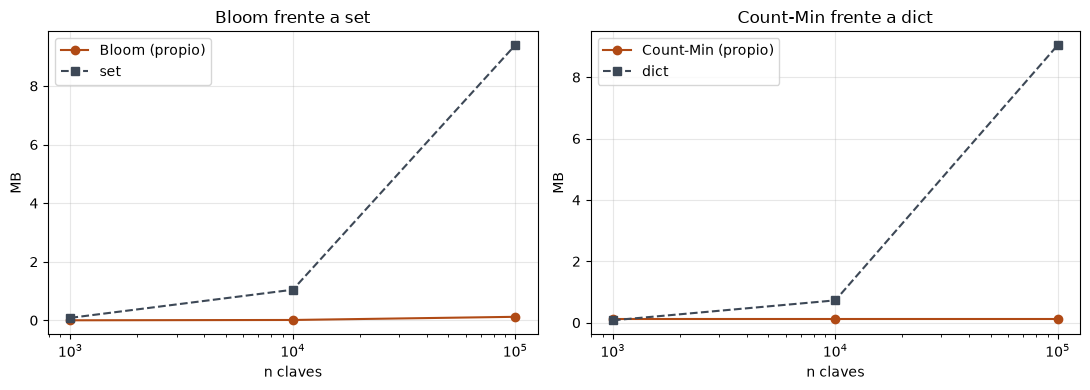

Con 100K claves: Bloom 0,12 MB frente a set 9,39 MB  |  Count-Min 0,11 MB (fija) frente a dict 9,04 MB


In [15]:
from src.etapa6_probabilistico import CountMinSketch, FiltroBloom

tamanos = [1_000, 10_000, 100_000]
bloom_mb, set_mb, cm_mb, dict_mb = [], [], [], []
for n in tamanos:
    claves = [f"ip:{i:08x}" for i in range(n)]
    b = FiltroBloom(n_esperado=n, prob_fp=0.01); b.actualizar(claves)
    bloom_mb.append(b.memoria_bytes / 1e6)
    s = set(claves); set_mb.append((sys.getsizeof(s) + sum(sys.getsizeof(k) for k in claves)) / 1e6)
    c = CountMinSketch(epsilon=0.001, delta=0.01)
    for k in claves:
        c.sumar(k)
    cm_mb.append(c.memoria_bytes / 1e6)
    d = {k: 1 for k in claves}; dict_mb.append((sys.getsizeof(d) + sum(sys.getsizeof(k) for k in d)) / 1e6)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
for ax, propio, exacto, titulo, nombre in ((ax1, bloom_mb, set_mb, "Bloom frente a set", "Bloom (propio)"),
                                           (ax2, cm_mb, dict_mb, "Count-Min frente a dict", "Count-Min (propio)")):
    ax.plot(tamanos, propio, "o-", color=ACENTO, label=nombre)
    ax.plot(tamanos, exacto, "s--", color=GRIS, label=titulo.split()[-1])
    ax.set_title(titulo); ax.set_xscale("log"); ax.set_xlabel("n claves"); ax.set_ylabel("MB")
    ax.legend(); ax.grid(True, alpha=.3)
plt.tight_layout(); plt.show()
print(f"Con 100K claves: Bloom {num(bloom_mb[-1], 2)} MB frente a set {num(set_mb[-1], 2)} MB  |  "
      f"Count-Min {num(cm_mb[-1], 2)} MB (fija) frente a dict {num(dict_mb[-1], 2)} MB")

## 13. Real frente a sintético (opcional)

Corre el pipeline con las dos fuentes y compara lo que cambia con datos reales. Tarda la suma
de las dos corridas, así que está apagado por defecto: pon `COMPARAR = True` para usarlo.

In [16]:
COMPARAR = False


def medidas(p, cap, t):
    r = p.resumen()
    return {
        "eventos": num(r[0]["eventos_recibidos"]),
        "productos": num(r[3]["productos"]),
        "compras": num(r[8]["compras"]),
        "aristas del grafo": num(r[8]["aristas"]),
        "aciertos de la caché": f"{num(100 * p.simular_consultas(n=CONSULTAS_CACHE, semilla=SEMILLA), 1)} %",
        "caché (productos)": num(cap),
        "etapa 7 (s)": num(p.tiempos[7], 2),
        "total (s)": num(t, 1),
    }


if COMPARAR:
    filas = {}
    for fuente in ("sintetico", "real"):
        p, _, cap, t = correr(fuente)
        filas[fuente] = medidas(p, cap, t)
    print(f"{'':<22} {'sintético':>12} {'real':>12}")
    for clave in filas["sintetico"]:
        print(f"{clave:<22} {str(filas['sintetico'][clave]):>12} {str(filas['real'][clave]):>12}")
else:
    print("Comparación apagada: pon COMPARAR = True para correrla.")

Comparación apagada: pon COMPARAR = True para correrla.


## Conclusiones

In [17]:
v = pipe.ventas()
print(f"Con {descripcion}:")
print(f"- Las 10 etapas procesaron el stream en {num(total, 1)} s; la más lenta fue la {etapas[mas_lenta]} "
      f"({ETAPAS[etapas[mas_lenta]]}).")
print(f"- La etapa 6 marcó {num(resumen[6]['marcados'])} eventos (precisión {num(resumen[6]['precision'], 2)}, "
      f"recall {num(resumen[6]['recall'], 2)}) y la etapa 2 los atendió primero.")
print(f"- La caché LRU, con el {num(100 * capacidad_cache / catalogo, 0)} % del catálogo, resolvió el {num(100 * tasa, 1)} % de las consultas.")
print(f"- El grafo tiene {num(m8['productos'])} productos; PageRank y grado tienen una correlación de Spearman de "
      f"{num(correlacion_rangos(pr, grado), 2)} y comparten {len(set(top_pr) & set(top_grado))} de 10 productos en el Top-10.")

Con 10.000 eventos sintéticos:
- Las 10 etapas procesaron el stream en 1,1 s; la más lenta fue la 7 (Similitud aproximada (IVF y MinHash + LSH)).
- La etapa 6 marcó 613 eventos (precisión 1,00, recall 1,00) y la etapa 2 los atendió primero.
- La caché LRU, con el 10 % del catálogo, resolvió el 48,5 % de las consultas.
- El grafo tiene 367 productos; PageRank y grado tienen una correlación de Spearman de 0,82 y comparten 10 de 10 productos en el Top-10.


El hilo común es el de estructuras de datos: elegir *dónde vive cada dato* (cola, heap, tabla
hash, B+Tree, grafo, índices aproximados) para ganar en complejidad y memoria, que es lo que
permite escalar a millones de eventos.